In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [13]:
df = pd.read_csv('churn.csv')

In [51]:
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0-6
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,25-36
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0-6
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,37-48
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0-6
5,9305-CDSKC,Female,No,No,No,8,Yes,Yes,Fiber optic,No,...,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,Yes,7-12
6,1452-KIOVK,Male,No,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.40,No,13-24
7,6713-OKOMC,Female,No,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,Month-to-month,No,Mailed check,29.75,301.90,No,7-12
8,7892-POOKP,Female,No,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,25-36
9,6388-TABGU,Male,No,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No,61-72


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


**Replace blanks in TotalCharges to 0 and Change Total Charges column data type to Float.**

In [16]:
df["TotalCharges"] = df["TotalCharges"].replace(" ", "0")
df["TotalCharges"] = df["TotalCharges"].astype("float")

In [17]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


**Checking null values per column,
Descriptive Analysis,
Duplicate values in primary key column**

In [18]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [19]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
df["customerID"].duplicated().sum()

np.int64(0)

**Change SeniorCitizen values to yes/No using function**

In [22]:
def conv(value):
    if value==1:
        return "Yes"
    else:
        return "No"

df["SeniorCitizen"]=df["SeniorCitizen"].apply(conv)

In [23]:
df["SeniorCitizen"].unique()

array(['No', 'Yes'], dtype=object)

**Data Analysis**

In [24]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

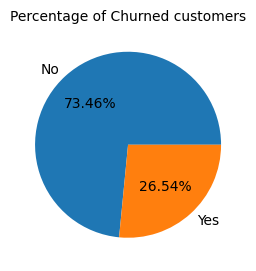

In [25]:
plt.figure(figsize=(3,4))
gb = df.groupby("Churn").agg({"Churn":"count"})
plt.pie(gb["Churn"], labels = gb.index, autopct = "%1.2f%%")
plt.title("Percentage of Churned customers", fontsize = 10)
plt.show()


From the above pie chart we conclude that 26.54 % of our customers have churned out.
Let's explore the reasons behind it.


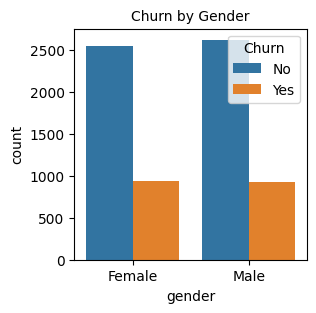

In [31]:
plt.figure(figsize=(3,3))
sns.countplot(x = "gender", data = df, hue = "Churn")
plt.title("Churn by Gender", fontsize = 10)
plt.show()

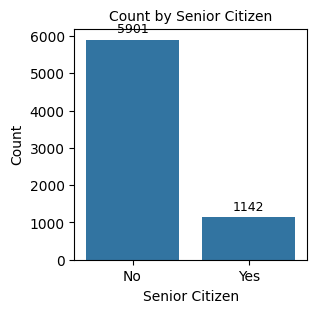

In [35]:
plt.figure(figsize=(3,3))

ax = sns.countplot(x="SeniorCitizen", data=df)

plt.title("Count by Senior Citizen", fontsize=10)
plt.xlabel("Senior Citizen")
plt.ylabel("Count")

# Add count labels above bars
for container in ax.containers:
    ax.bar_label(container, fontsize=9, padding=3)

plt.show()

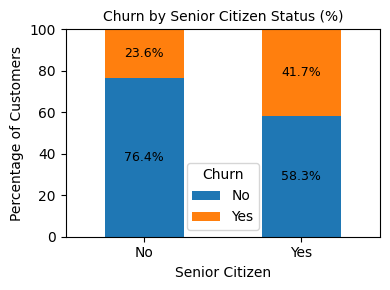

In [43]:
churn_pct = (
    pd.crosstab(df["SeniorCitizen"], df["Churn"], normalize="index") * 100
)

# Plot 100% stacked column chart
ax = churn_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(4, 3)
)

plt.title("Churn by Senior Citizen Status (%)", fontsize=10)
plt.xlabel("Senior Citizen")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")

# Display percentage values inside each section
for container in ax.containers:
    labels = [f"{v:.1f}%" if v > 0 else "" for v in container.datavalues]
    ax.bar_label(container, labels=labels, label_type="center", fontsize=9)

plt.ylim(0, 100)
plt.tight_layout()
plt.show()

Comparatively a greater percenage of senior ciizens are churned out.

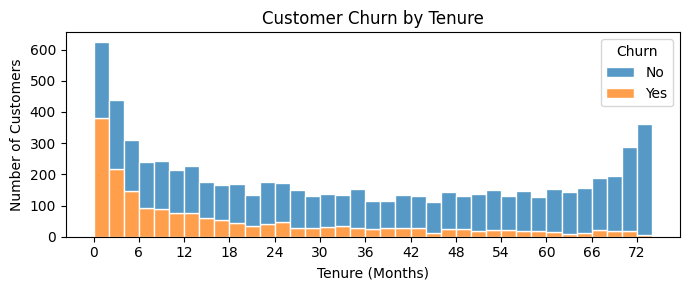

In [44]:
plt.figure(figsize=(7, 3))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=range(0, 76, 2),   # 2-month intervals
    multiple="stack",
    edgecolor="white"
)

plt.title("Customer Churn by Tenure", fontsize=12)
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.xticks(range(0, 73, 6))
plt.tight_layout()
plt.show()

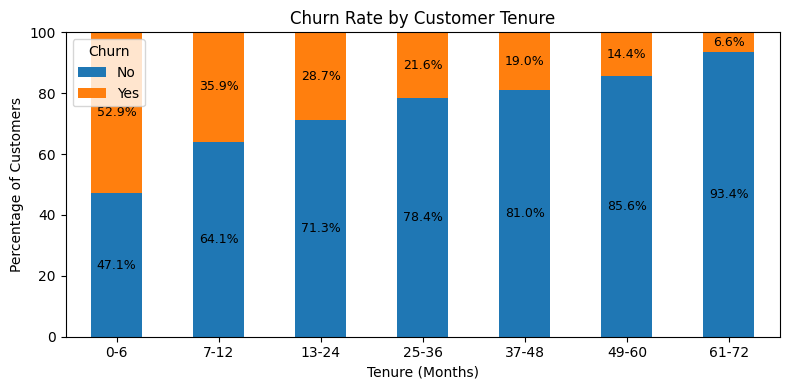

In [52]:
bins = [0, 6, 12, 24, 36, 48, 60, 72]
labels = [
    "0-6",
    "7-12",
    "13-24",
    "25-36",
    "37-48",
    "49-60",
    "61-72"
]

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Calculate churn percentage within each tenure group
churn_pct = (
    pd.crosstab(
        df["TenureGroup"],
        df["Churn"],
        normalize="index"
    ) * 100
)

# Plot 100% stacked columns
ax = churn_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 4)
)

plt.title("Churn Rate by Customer Tenure", fontsize=12)
plt.xlabel("Tenure (Months)")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Churn")

# Percentage labels
for container in ax.containers:
    labels = [
        f"{v:.1f}%" if v >= 5 else ""
        for v in container.datavalues
    ]
    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

**More people churn out during first one year of tenure.**

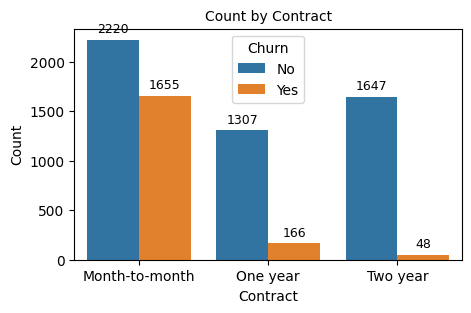

In [45]:
plt.figure(figsize=(5,3))

ax = sns.countplot(x="Contract", data=df, hue = "Churn")

plt.title("Count by Contract", fontsize=10)
plt.xlabel("Contract")
plt.ylabel("Count")

# Add count labels above bars
for container in ax.containers:
    ax.bar_label(container, fontsize=9, padding=3)

plt.show()

**People with month to month contract are more likely to churn than those having one or two years of contract. Encourage people to get contract for one or two year by giving discounts or schemes.**

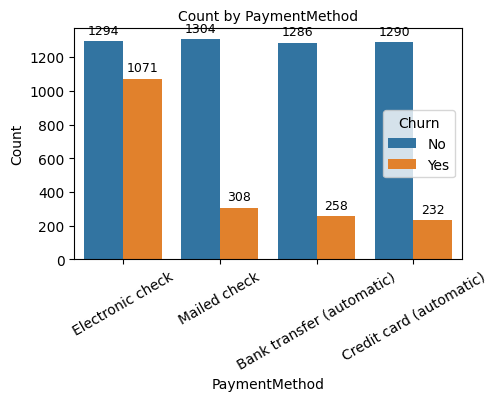

In [48]:
plt.figure(figsize=(5,3))

ax = sns.countplot(x="PaymentMethod", data=df, hue = "Churn")

plt.title("Count by PaymentMethod", fontsize=10)
plt.xlabel("PaymentMethod")
plt.ylabel("Count")
ax.tick_params(axis='x', rotation=30)

# Add count labels above bars
for container in ax.containers:
    ax.bar_label(container, fontsize=9, padding=3)

plt.show()

**Customers with Payment method of electronic check are more likely to churn than other payment methods.**

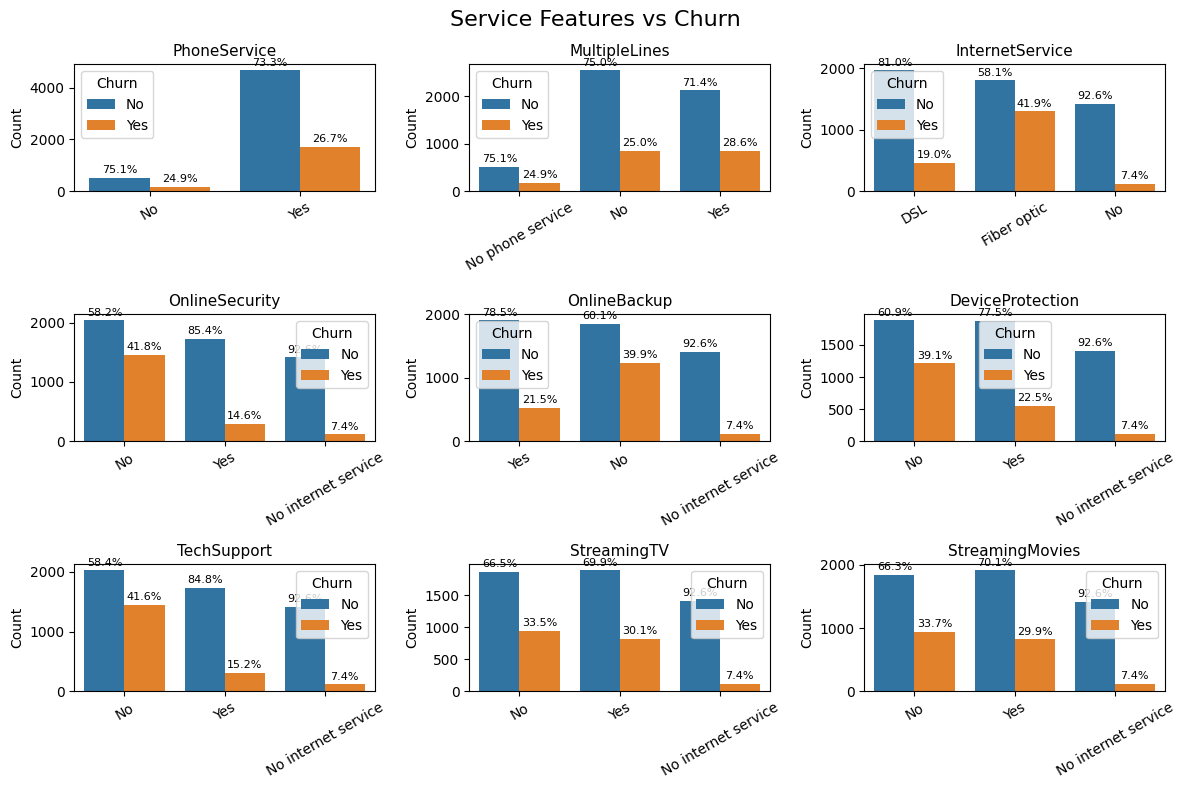

In [50]:
cols = [
    'PhoneService',
    'MultipleLines',
    'InternetService',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

fig, axes = plt.subplots(3, 3, figsize=(12, 8))
axes = axes.flatten()

for ax, col in zip(axes, cols):

    # Create countplot
    sns.countplot(
        data=df,
        x=col,
        hue='Churn',
        ax=ax
    )

    # Calculate percentages within each category
    category_totals = df[col].value_counts()

    # Add percentage labels
    for container in ax.containers:
        labels = []

        for bar in container:
            height = bar.get_height()

            if height > 0:
                category = bar.get_x() + bar.get_width()/2

                # Get x tick labels
                x_labels = [tick.get_text() for tick in ax.get_xticklabels()]

                # Find corresponding category
                index = round(category)
                if 0 <= index < len(x_labels):
                    cat_name = x_labels[index]
                    pct = height / category_totals[cat_name] * 100
                    labels.append(f'{pct:.1f}%')
                else:
                    labels.append('')
            else:
                labels.append('')

        ax.bar_label(container, labels=labels, fontsize=8, padding=2)

    ax.set_title(col, fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("Count")
    ax.tick_params(axis='x', rotation=30)

plt.suptitle("Service Features vs Churn", fontsize=16)
plt.tight_layout()
plt.show()

1. Very little difference between customers with and without phone service. Phone service alone is not a strong churn driver.
2. Multi-line customers are not significantly more loyal.
3. Fiber optic customers and customers without Tech Support churn more than other. Offering discounted support to Fiber customers could significantly reduce churn.
4. Customers without Online Security churn nearly 3 times more than customers who have it.
5. Customers with online backup and protection services show substantially lower churn.
6. Streaming TV and movies services doen not affect the churn rate much.